# Phase 1 - Data preparation

## Setup and Imports

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

from scipy.stats import ks_2samp

import plotly.graph_objects as go
import plotly.express as px

## 1. Dataset Loading

In [2]:
data_path = "../data/Customer_Churn_dataset.csv"
if data_path is None:
    raise FileNotFoundError(
        "Could not find data/Customer_Churn_dataset.csv from the notebook or repository root."
    )

df = pd.read_csv(data_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Initial Data Inspection

Review the dataset dimensions, column data types, and missing values before converting `TotalCharges`.

In [3]:
print(f"Dataset dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
column_info = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing_values": df.isna().sum(),
    }
)
display(column_info)
print("Total missing values before numeric conversion:", int(df.isna().sum().sum()))

Dataset dimensions: 7043 rows x 21 columns


,dtype,missing_values
customerID,object,0
gender,object,0
SeniorCitizen,int64,0
Partner,object,0
Dependents,object,0
tenure,int64,0
PhoneService,object,0
MultipleLines,object,0
InternetService,object,0
OnlineSecurity,object,0


Total missing values before numeric conversion: 0


## 3. Data Cleaning and Preprocessing

`TotalCharges` is stored as text, so it is converted to numeric with invalid entries coerced to missing values. Rows with missing values are then removed, and `customerID` is dropped because it is an identifier rather than a model feature.

In [4]:
rows_before_cleaning = len(df)
missing_before_conversion = int(df.isna().sum().sum())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_after_conversion = int(df.isna().sum().sum())
print("Missing values before numeric conversion:", missing_before_conversion)
print("Missing values after numeric conversion:", missing_after_conversion)

df = df.dropna()
rows_removed = rows_before_cleaning - len(df)
print("Rows removed during missing-value handling:", rows_removed)

df = df.drop(columns=["customerID"])

Missing values before numeric conversion: 0
Missing values after numeric conversion: 11
Rows removed during missing-value handling: 11


## 4. Target Variable Encoding

Map the binary target to `1` for churn and `0` for no churn

In [5]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

## 5. Categorical Feature Encoding

Categorical features are encoded using scikit-learn's `LabelEncoder`, applied separately to each categorical column. 

In [6]:
categorical_cols = df.select_dtypes(include=["object"]).columns

le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

## 6. Feature-Target Separation

In [7]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

## 7. Train-Test Split (70:30)

In [8]:
split_index = int(0.7 * len(df))

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

## 8. Split Verification

In [9]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train class counts (Churn):\n", y_train.value_counts().sort_index().rename(index={0: "No", 1: "Yes"}))
print("Test class counts (Churn):\n", y_test.value_counts().sort_index().rename(index={0: "No", 1: "Yes"}))

Train shape: (4922, 19)
Test shape: (2110, 19)
Train class counts (Churn):
 Churn
No     3633
Yes    1289
Name: count, dtype: int64
Test class counts (Churn):
 Churn
No     1530
Yes     580
Name: count, dtype: int64


## 9. Preservation of Original Test Data

In [10]:
X_test_original = X_test.copy()
y_test_original = y_test.copy()

assert X_test_original.equals(X_test)
assert y_test_original.equals(y_test)
print("Original test copies:", X_test_original.shape, y_test_original.shape)

Original test copies: (2110, 19) (2110,)


# Phase 2 - Baseline model training & metrics

## 1. Train model

In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

## 2. Predictions on Baseline Test Data

In [ ]:
y_pred = model.predict(X_test)

## 3. Model evaluation

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.7881516587677725
Precision: 0.6587112171837709
Recall: 0.47586206896551725
F1 Score: 0.5525525525525525


Confusion matrix

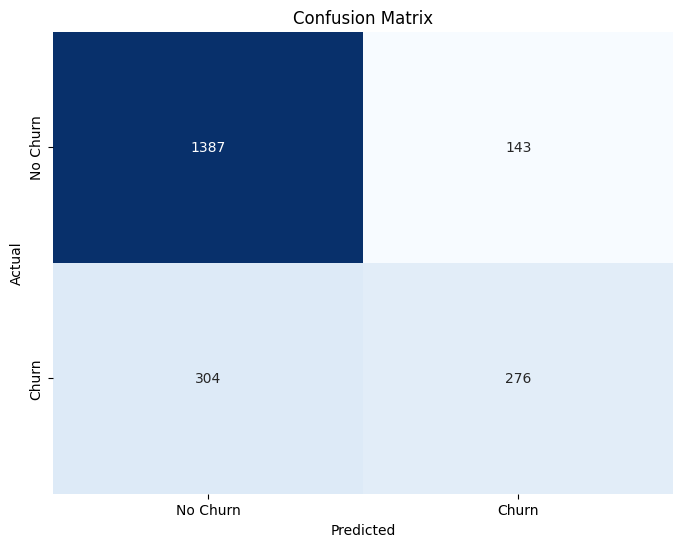

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1530
           1       0.66      0.48      0.55       580

    accuracy                           0.79      2110
   macro avg       0.74      0.69      0.71      2110
weighted avg       0.78      0.79      0.78      2110



## 4. Save Baseline Metrics

In [ ]:
baseline_metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1
}

baseline_metrics

{'accuracy': 0.7881516587677725,
 'precision': 0.6587112171837709,
 'recall': 0.47586206896551725,
 'f1_score': 0.5525525525525525}

# Phase 3 - Drift simulation

## 1. Create Drifted Dataset

In [ ]:
X_drifted = X_test_original.copy()
y_drifted = y_test_original.copy()

### 1.1 DRIFT TYPE 1: Feature Distribution Shift
Modify numerical columns only.

In [ ]:
# Identify Numerical Columns
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Apply Controlled Drift
np.random.seed(42)
for col in num_cols:
    drift_factor = np.random.uniform(0.1, 0.3)  # 10%–30% shift
    X_drifted[col] = X_drifted[col] * (1 + drift_factor)

### 1.2 DRIFT TYPE 2: Class Imbalance Shift
Artificially increase churn rate.

In [ ]:
# Increase churn probability for specific segment (e.g., high MonthlyCharges)

threshold = X_drifted["MonthlyCharges"].quantile(0.75)

high_risk_idx = X_drifted[X_drifted["MonthlyCharges"] > threshold].index

flip_indices = high_risk_idx[:int(0.05 * len(X_drifted))]

y_drifted.loc[flip_indices] = 1

## 2. Verify drift

### Check Target Distribution

In [ ]:
print("Before Drift:")
print(y_test_original.value_counts(normalize=True))

print("\nAfter Drift:")
print(y_drifted.value_counts(normalize=True))

Before Drift:
Churn
0    0.725118
1    0.274882
Name: proportion, dtype: float64

After Drift:
Churn
0    0.654976
1    0.345024
Name: proportion, dtype: float64


### Check Feature Mean Shift

In [ ]:
print("Before Drift:")
print(X_test_original[num_cols].mean())

print("\nAfter Drift:")
print(X_drifted[num_cols].mean())

Before Drift:
tenure              32.496682
MonthlyCharges      64.565071
TotalCharges      2285.749005
dtype: float64

After Drift:
tenure              38.180613
MonthlyCharges      83.298166
TotalCharges      2848.954790
dtype: float64


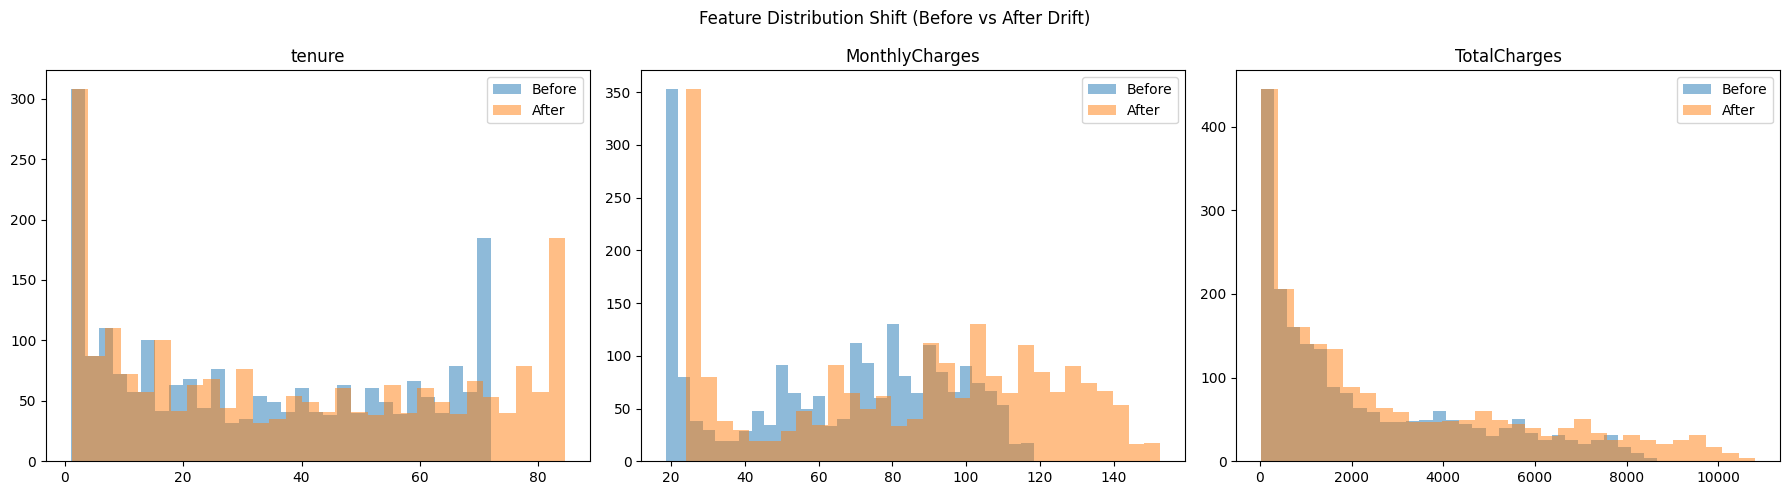

In [ ]:
import matplotlib.pyplot as plt

cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(cols):
    axes[i].hist(X_test_original[col], bins=30, alpha=0.5, label="Before")
    axes[i].hist(X_drifted[col], bins=30, alpha=0.5, label="After")
    axes[i].set_title(col)
    axes[i].legend()

plt.suptitle("Feature Distribution Shift (Before vs After Drift)")
plt.tight_layout()
plt.show()

## 3. Save Drifted Dataset

In [ ]:
X_drifted_final = X_drifted.copy()
y_drifted_final = y_drifted.copy()

# Phase 4 - Drift Detection

## 1. KS TEST (Kolmogorov–Smirnov Test)

In [ ]:
cols = ["tenure", "MonthlyCharges", "TotalCharges"]

ks_results = {}

for col in cols:
    stat, p_value = ks_2samp(X_test_original[col], X_drifted[col])

    ks_results[col] = {
        "KS Statistic": stat,
        "p-value": p_value
    }

ks_results

{'tenure': {'KS Statistic': np.float64(0.1819905213270142),
  'p-value': np.float64(6.139795835301714e-31)},
 'MonthlyCharges': {'KS Statistic': np.float64(0.2938388625592417),
  'p-value': np.float64(1.0496143319796195e-80)},
 'TotalCharges': {'KS Statistic': np.float64(0.08104265402843602),
  'p-value': np.float64(1.893540129997992e-06)}}

## 2. PSI (Population Stability Index)

In [ ]:
def calculate_psi(expected, actual, bins=10):

    expected_percents, bin_edges = np.histogram(expected, bins=bins)
    actual_percents, _ = np.histogram(actual, bins=bin_edges)

    expected_percents = expected_percents / len(expected)
    actual_percents = actual_percents / len(actual)

    psi_values = (expected_percents - actual_percents) * np.log(
        (expected_percents + 1e-6) / (actual_percents + 1e-6)
    )

    return np.sum(psi_values)

In [ ]:
psi_results = {}

for col in cols:
    psi = calculate_psi(X_test_original[col], X_drifted[col])
    psi_results[col] = psi

psi_results

{'tenure': np.float64(0.09325412673582249),
 'MonthlyCharges': np.float64(0.30033013220164473),
 'TotalCharges': np.float64(0.02755246456691579)}

## 3. Results table

In [ ]:
import pandas as pd

results_df = pd.DataFrame({
    "Feature": cols,
    "KS Statistic": [ks_results[c]["KS Statistic"] for c in cols],
    "p-value": [ks_results[c]["p-value"] for c in cols],
    "PSI": [psi_results[c] for c in cols]
})

results_df

,Feature,KS Statistic,p-value,PSI
0,tenure,0.181991,6.139796e-31,0.093254
1,MonthlyCharges,0.293839,1.049614e-80,0.300330
2,TotalCharges,0.081043,1.893540e-06,0.027552


# Phase 5 - Performance Impact Analysis

## 1. Evaluate Model on Drifted Data

In [ ]:
y_pred_drifted = model.predict(X_drifted_final)

# Calculate Metrics on Drifted Data
accuracy_drifted = accuracy_score(y_drifted_final, y_pred_drifted)
precision_drifted = precision_score(y_drifted_final, y_pred_drifted)
recall_drifted = recall_score(y_drifted_final, y_pred_drifted)
f1_drifted = f1_score(y_drifted_final, y_pred_drifted)

drifted_metrics = {
    "accuracy": accuracy_drifted,
    "precision": precision_drifted,
    "recall": recall_drifted,
    "f1_score": f1_drifted
}

drifted_metrics

{'accuracy': 0.7350710900473933,
 'precision': 0.7026378896882494,
 'recall': 0.4024725274725275,
 'f1_score': 0.5117903930131005}

## 2. Compare Baseline vs Drifted

In [ ]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Baseline": [
        baseline_metrics["accuracy"],
        baseline_metrics["precision"],
        baseline_metrics["recall"],
        baseline_metrics["f1_score"]
    ],
    "Drifted": [
        drifted_metrics["accuracy"],
        drifted_metrics["precision"],
        drifted_metrics["recall"],
        drifted_metrics["f1_score"]
    ]
})

comparison_df["Drop"] = comparison_df["Baseline"] - comparison_df["Drifted"]
comparison_df

,Metric,Baseline,Drifted,Drop
0,Accuracy,0.788152,0.735071,0.053081
1,Precision,0.658711,0.702638,-0.043927
2,Recall,0.475862,0.402473,0.073390
3,F1 Score,0.552553,0.511790,0.040762


<Axes: xlabel='Metric'>

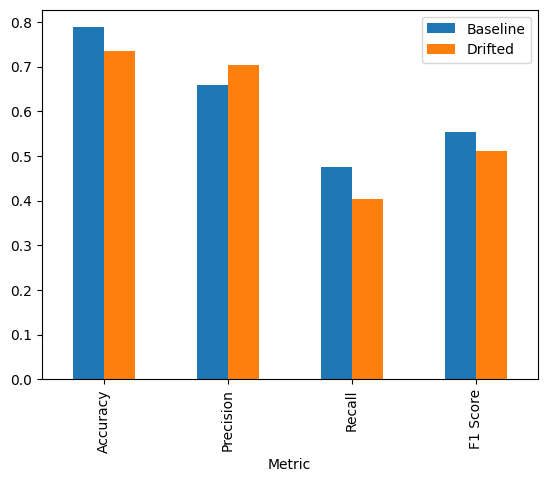

In [ ]:
comparison_df.set_index("Metric")[["Baseline", "Drifted"]].plot(kind="bar")

# Phase 6 - Retraining Trigger + Response Mechanism

In [ ]:
def monitor_and_retrain(model, X_test_original, X_drifted, y_drifted, cols, psi_results):

    # Step 1: Check Drift Status
    def check_drift(psi_value):
        if psi_value > 0.25:
            return "High Drift"
        elif psi_value > 0.1:
            return "Moderate Drift"
        else:
            return "No Drift"

    drift_status = {col: check_drift(psi_results[col]) for col in cols}

    print("Drift Status:", drift_status)


    # Step 2: Decide if retraining is needed
    retrain_flag = any(status == "High Drift" for status in drift_status.values())

    print("Retraining Triggered:", retrain_flag)


    # Step 3: If drift detected → retrain
    if retrain_flag:
        print("\n🚨 High drift detected! Retraining model...\n")

        new_model = RandomForestClassifier(n_estimators=100, random_state=42)
        new_model.fit(X_drifted, y_drifted)

        return new_model, drift_status

    else:
        print("\n✅ No significant drift. Using existing model.\n")
        return model, drift_status

In [ ]:
# Split drifted data
X_train_drift, X_test_drift, y_train_drift, y_test_drift = train_test_split(
    X_drifted_final, y_drifted_final, test_size=0.3, random_state=42
)

final_model, drift_status = monitor_and_retrain(
    model,
    X_test_original,
    X_train_drift,
    y_train_drift,
    cols,
    psi_results
)

Drift Status: {'tenure': 'No Drift', 'MonthlyCharges': 'High Drift', 'TotalCharges': 'No Drift'}
Retraining Triggered: True

🚨 High drift detected! Retraining model...



### Evaluate retrained model on drifted data

In [ ]:
y_pred_final = final_model.predict(X_test_drift)

final_metrics = {
    "accuracy": accuracy_score(y_test_drift, y_pred_final),
    "precision": precision_score(y_test_drift, y_pred_final),
    "recall": recall_score(y_test_drift, y_pred_final),
    "f1_score": f1_score(y_test_drift, y_pred_final)
}

# Phase 7 - Dashboard

In [ ]:
# Prepare final results (for dashboard + summary)

final_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Baseline": [
        baseline_metrics["accuracy"],
        baseline_metrics["precision"],
        baseline_metrics["recall"],
        baseline_metrics["f1_score"]
    ],
    "Drifted": [
        drifted_metrics["accuracy"],
        drifted_metrics["precision"],
        drifted_metrics["recall"],
        drifted_metrics["f1_score"]
    ],
    "Retrained": [
        final_metrics["accuracy"],
        final_metrics["precision"],
        final_metrics["recall"],
        final_metrics["f1_score"]
    ]
})

## 1. PSI Bar Chart

In [ ]:
psi_df = pd.DataFrame({
    "Feature": cols,
    "PSI": [psi_results[col] for col in cols]
})

fig_psi = px.bar(
    psi_df,
    x="Feature",
    y="PSI",
    title="Drift Monitoring (PSI Values)",
    color="PSI",
    color_continuous_scale="Reds"
)

fig_psi.add_hline(y=0.25, line_dash="dash", annotation_text="High Drift Threshold")

fig_psi.update_traces(
    text=psi_df["PSI"].round(3),
    textposition="outside"
)

fig_psi.show()

## 2. Performance Recovery

In [ ]:
perf_df = final_results.melt(id_vars="Metric",
                            value_vars=["Baseline", "Drifted", "Retrained"])

fig_perf = px.line(
    perf_df,
    x="variable",
    y="value",
    color="Metric",
    markers=True,
    title="Model Performance Across Lifecycle"
)

fig_perf.show()

# Result summary

In [ ]:
import pandas as pd

# Create final comparison table - Add performance drop & recovery
final_results["Drop (Baseline→Drifted)"] = final_results["Baseline"] - final_results["Drifted"]
final_results["Recovery (Drifted→Retrained)"] = final_results["Retrained"] - final_results["Drifted"]

# Display
print("=== FINAL PERFORMANCE COMPARISON ===\n")
display(final_results)


=== FINAL PERFORMANCE COMPARISON ===



,Metric,Baseline,Drifted,Retrained,Drop (Baseline→Drifted),Recovery (Drifted→Retrained)
0,Accuracy,0.788152,0.735071,0.685624,0.053081,-0.049447
1,Precision,0.658711,0.702638,0.707317,-0.043927,0.004679
2,Recall,0.475862,0.402473,0.434457,0.073390,0.031984
3,F1 Score,0.552553,0.511790,0.538283,0.040762,0.026493
